# Trocando o LM Head: classificação de sentimentos com BERT

**Projeto da Aula 09 — Fundamentos de LLMs (Ajustando um LLM)**

Na aula pegamos o **Llama 3.2 1B**, removemos o *LM Head* (a camada final que escolhe o próximo token)
e colocamos no lugar uma camada de classificação com **apenas 2 neurônios**: *negativo* e *positivo*.

Neste projeto fazemos **a mesma ideia com outro backbone, o BERT**, e aproveitamos para responder
ao exercício 1 da aula: **o que muda se treinarmos só a cabeça nova (transfer learning) em vez do modelo
inteiro (fine-tuning)?**

## A ideia em um desenho

```
              Modelo de linguagem "normal" (como vem do Hugging Face)
texto ──► [ corpo: camadas Transformer ] ──► [ LM Head: 768 → 30.522 ] ──► próximo token
                                              (1 neurônio por token do vocabulário)

              O que fazemos neste projeto
texto ──► [ corpo: camadas Transformer ] ──► [ cabeça nova: 768 → 2 ] ──► negativo / positivo
```

**Analogia:** o corpo do modelo é um leitor experiente, que já entende inglês muito bem.
O LM Head é a "boca" dele, que responde escolhendo uma palavra entre 30 mil.
Para dizer se uma crítica de filme é boa ou ruim, não precisamos de 30 mil palavras:
trocamos a boca por um **painel com dois botões**. O painel é novo, então precisa ser treinado.

## Por que BERT?

| | Llama 3.2 1B (aula) | BERT base (este projeto) |
|---|---|---|
| Tipo | *decoder* (gera texto) | *encoder* (entende texto) |
| Como lê a frase | da esquerda para a direita (máscara causal: o "triângulo" dos mapas de atenção) | a frase inteira de uma vez (atenção bidirecional) |
| Qual vetor vai para a cabeça | o do **último** token | o do token especial **[CLS]**, no início |
| Parâmetros | ~1,2 bilhão | ~110 milhões (~11x menor) |
| Precisa de token do Hugging Face? | sim (modelo restrito) | não |

O BERT (Devlin et al., 2018) foi criado justamente para ser ajustado em tarefas como esta, então é o
backbone "clássico" sugerido no slide de exercícios.

## Roteiro

1. Configuração
2. Dados (SST-2, o mesmo da aula)
3. Tokenizador
4. Funções auxiliares (carregar, treinar, avaliar)
5. Experimento A — fine-tuning completo
6. Experimento B — transfer learning (corpo congelado)
7. Comparação dos resultados
8. Testando frases novas
9. Conclusões

In [1]:
# Rode só se precisar (no Google Colab quase tudo já vem instalado).
# !pip install -q -U transformers datasets accelerate

## 1. Configuração

Todos os "botões" do experimento ficam nesta célula. Quando quiser testar algo diferente
(outro modelo, mais épocas, mais dados), mude só aqui e rode o notebook de novo.

Usamos os **mesmos valores da aula** (1000 frases de treino, lote de 8, 3 épocas, taxa de aprendizado 2e-5)
para a comparação com o Llama ser justa.

In [2]:
import time       # para medir quanto tempo cada treinamento leva
import random     # aleatoriedade do Python
import numpy as np
import torch

# ------------------------- Botões do experimento -------------------------
MODEL_ID = "bert-base-uncased"  # backbone pré-treinado ("uncased" = ignora maiúsculas/minúsculas)
NUM_TREINO = 1000               # quantas frases de treino usar (igual à aula)
MAX_LENGTH = 64                 # tamanho máximo de cada frase, em tokens (as do SST-2 são curtas)
BATCH_SIZE = 8                  # quantas frases o modelo vê por passo de treinamento (igual à aula)
NUM_EPOCAS = 3                  # quantas vezes o modelo passa pelo conjunto de treino (igual à aula)
LR_FINE_TUNING = 2e-5           # taxa de aprendizado do fine-tuning completo (igual à aula)
LR_TRANSFER = 1e-3              # taxa maior para o transfer learning (explicada no Experimento B)
SEED = 42                       # "semente": faz os sorteios saírem iguais toda vez que rodamos

# Usa a GPU se existir; senão, a CPU (mais lento, mas funciona: o BERT é pequeno).
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


def fixar_semente(seed=SEED):
    # Fixa todos os sorteios: embaralhamento dos dados, pesos iniciais da cabeça e dropout.
    # Assim, rodar o notebook de novo dá (quase) o mesmo resultado.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

Dispositivo: cuda
GPU: NVIDIA GeForce RTX 5080


## 2. Dados: SST-2

O **SST-2** (*Stanford Sentiment Treebank*) tem trechos curtos de críticas de cinema em inglês,
rotulados como `0 = negativo` ou `1 = positivo`.

Como na aula, o conjunto de **teste** do SST-2 não tem rótulos públicos, então usamos a **validação**
(872 frases) como se fosse o teste: o modelo **nunca** treina com ela.

In [3]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/sst2")

# Embaralha o treino (com semente fixa) e pega só as primeiras NUM_TREINO frases.
treino = dataset["train"].shuffle(seed=SEED).select(range(NUM_TREINO))
validacao = dataset["validation"]

print("Frases de treino:   ", len(treino))
print("Frases de validação:", len(validacao))

NOMES = {0: "negativo", 1: "positivo"}

print("\nAlguns exemplos de treino:")
for i in range(5):
    print(f"  [{NOMES[treino[i]['label']]}] {treino[i]['sentence']}")

Frases de treino:    1000
Frases de validação: 872

Alguns exemplos de treino:
  [positivo] klein , charming in comedies like american pie and dead-on in election , 
  [positivo] be fruitful 
  [positivo] soulful and 
  [positivo] the proud warrior that still lingers in the souls of these characters 
  [negativo] covered earlier and much better 


Antes de treinar qualquer coisa, vale ver se as classes estão **equilibradas**. Isso nos dá a
"nota mínima" que qualquer modelo precisa superar: um "chute" que responde sempre a classe
mais comum já acerta essa porcentagem.

In [4]:
positivos_val = sum(validacao["label"])
chute = max(positivos_val, len(validacao) - positivos_val) / len(validacao)

print(f"Positivos no treino:    {sum(treino['label'])} de {len(treino)}")
print(f"Positivos na validação: {positivos_val} de {len(validacao)}")
print(f"Acurácia de quem 'chuta' sempre a classe mais comum: {chute:.1%}")

Positivos no treino:    557 de 1000
Positivos na validação: 444 de 872
Acurácia de quem 'chuta' sempre a classe mais comum: 50.9%


## 3. Tokenizador

Cada modelo tem o seu tokenizador, que quebra o texto em pedaços (tokens) e troca cada pedaço por um número.

In [5]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

print("Tamanho do vocabulário:", tokenizer.vocab_size)
print("Token de padding:", tokenizer.pad_token, "| id:", tokenizer.pad_token_id)

texto = "This movie is absolutely fantastic!"
ids = tokenizer(texto)["input_ids"]

print("\nTexto: ", texto)
print("Tokens:", tokenizer.convert_ids_to_tokens(ids))
print("IDs:   ", ids)

Tamanho do vocabulário: 30522
Token de padding: [PAD] | id: 0

Texto:  This movie is absolutely fantastic!
Tokens: ['[CLS]', 'this', 'movie', 'is', 'absolutely', 'fantastic', '!', '[SEP]']
IDs:    [101, 2023, 3185, 2003, 7078, 10392, 999, 102]


**O que mudou em relação ao Llama da aula:**

- O BERT **já tem um token de padding** (`[PAD]`). Na aula tivemos que improvisar usando o token de fim de texto do Llama.
- Toda frase começa com **`[CLS]`** e termina com **`[SEP]`**. O vetor que o BERT produz para o `[CLS]` funciona
  como um "resumo" da frase inteira, e **é ele que entra na cabeça de classificação**.
- O vocabulário é bem menor: 30.522 tokens contra 128.000 do Llama. Palavras raras são quebradas em
  subpalavras marcadas com `##` (ex.: `fantastic` poderia virar `fan` + `##tastic`).
- Por ser *uncased*, tudo vira minúsculo.

Agora tokenizamos os dois conjuntos. Primeiro conferimos se `MAX_LENGTH = 64` é suficiente,
para não cortar o final de nenhuma frase:

In [6]:
maior_treino = max(len(tokenizer(s)["input_ids"]) for s in treino["sentence"])
maior_val = max(len(tokenizer(s)["input_ids"]) for s in validacao["sentence"])
print("Maior frase do treino (tokens):   ", maior_treino)
print("Maior frase da validação (tokens):", maior_val)
print("MAX_LENGTH:", MAX_LENGTH)

Maior frase do treino (tokens):    53
Maior frase da validação (tokens): 55
MAX_LENGTH: 64


In [7]:
def tokenizar(lote):
    # padding="max_length": completa as frases curtas com [PAD] até MAX_LENGTH,
    # para que todas tenham o mesmo tamanho e caibam juntas em um lote (batch).
    # truncation=True: corta frases maiores que MAX_LENGTH (pela célula acima, nenhuma é cortada).
    return tokenizer(lote["sentence"], padding="max_length", truncation=True, max_length=MAX_LENGTH)


treino = treino.map(tokenizar, batched=True)
validacao = validacao.map(tokenizar, batched=True)

# Diz à biblioteca para entregar estas colunas como tensores do PyTorch.
colunas = ["input_ids", "attention_mask", "label"]
treino.set_format("torch", columns=colunas)
validacao.set_format("torch", columns=colunas)

from torch.utils.data import DataLoader

# O DataLoader entrega os dados em lotes de BATCH_SIZE frases.
treino_loader = DataLoader(treino, batch_size=BATCH_SIZE, shuffle=True)        # embaralha a cada época
validacao_loader = DataLoader(validacao, batch_size=BATCH_SIZE, shuffle=False)

print("Lotes de treino por época:", len(treino_loader))

Lotes de treino por época: 125


## 4. Funções auxiliares

Vamos rodar **dois** experimentos com o mesmo modelo de partida. Para não repetir código,
criamos quatro funções:

- `carregar_modelo()` — baixa o BERT **sem** o LM Head e com uma cabeça nova de 2 neurônios;
- `contar_parametros()` — mostra quantos parâmetros existem e quantos vão aprender;
- `treinar()` — o mesmo laço de treinamento da aula;
- `avaliar()` — mede a acurácia na validação.

**Sobre o tipo numérico:** na aula o Llama foi carregado em `bfloat16` para caber na memória.
O BERT é pequeno, então usamos o padrão `float32`, que é mais preciso e evita problemas
de compatibilidade de GPU (a T4 do Colab, por exemplo, não acelera `bfloat16`).

In [8]:
from transformers import AutoModelForSequenceClassification


def carregar_modelo():
    # Mesma semente -> a cabeça nova nasce com os MESMOS pesos aleatórios nos dois experimentos.
    fixar_semente()

    # AutoModelForSequenceClassification faz a "cirurgia" por nós:
    # baixa o corpo pré-treinado, descarta o LM Head e cria uma cabeça com num_labels saídas.
    modelo = AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID,
        num_labels=2,
        id2label=NOMES,                                   # 0 -> "negativo", 1 -> "positivo"
        label2id={nome: i for i, nome in NOMES.items()},
    )
    return modelo.to(device)                              # leva o modelo para a GPU (ou CPU)


def contar_parametros(modelo):
    total = sum(p.numel() for p in modelo.parameters())
    # requires_grad=True significa "este parâmetro pode ser alterado pelo treinamento".
    treinaveis = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print(f"Parâmetros totais:     {total:>12,}")
    print(f"Parâmetros treináveis: {treinaveis:>12,}  ({treinaveis / total:.4%} do modelo)")
    return total, treinaveis


def treinar(modelo, lr, num_epocas=NUM_EPOCAS):
    # Só entregamos ao otimizador os parâmetros que podem aprender.
    # (No fine-tuning são todos; no transfer learning, só os da cabeça nova.)
    parametros = [p for p in modelo.parameters() if p.requires_grad]
    otimizador = torch.optim.AdamW(parametros, lr=lr, weight_decay=0.01)

    fixar_semente()      # mesmo embaralhamento dos lotes nos dois experimentos
    historico = []
    inicio = time.time()

    for epoca in range(num_epocas):
        modelo.train()   # modo treino (liga o dropout)
        soma_loss, acertos, total = 0.0, 0, 0

        for lote in treino_loader:
            input_ids = lote["input_ids"].to(device)
            attention_mask = lote["attention_mask"].to(device)   # 1 = token real, 0 = [PAD]
            rotulos = lote["label"].to(device)

            otimizador.zero_grad()                 # zera os gradientes do passo anterior
            saida = modelo(input_ids=input_ids,    # passada para frente (forward)
                           attention_mask=attention_mask,
                           labels=rotulos)         # com labels, o modelo já calcula a loss
            saida.loss.backward()                  # calcula os gradientes (backpropagation)
            otimizador.step()                      # ajusta os pesos na direção que reduz o erro

            soma_loss += saida.loss.item()
            acertos += (saida.logits.argmax(dim=1) == rotulos).sum().item()
            total += rotulos.size(0)

        historico.append({"epoca": epoca + 1,
                          "loss": soma_loss / len(treino_loader),
                          "acuracia": acertos / total})
        print(f"Época {epoca + 1}/{num_epocas}: loss = {historico[-1]['loss']:.4f}, "
              f"acurácia no treino = {historico[-1]['acuracia']:.1%}")

    tempo = time.time() - inicio
    print(f"Tempo de treinamento: {tempo:.1f} s")
    return historico, tempo


def avaliar(modelo):
    modelo.eval()        # modo avaliação (desliga o dropout)
    soma_loss, acertos, total = 0.0, 0, 0
    with torch.no_grad():  # sem gradientes: só queremos as respostas (mais rápido, menos memória)
        for lote in validacao_loader:
            rotulos = lote["label"].to(device)
            saida = modelo(input_ids=lote["input_ids"].to(device),
                           attention_mask=lote["attention_mask"].to(device),
                           labels=rotulos)
            soma_loss += saida.loss.item()
            acertos += (saida.logits.argmax(dim=1) == rotulos).sum().item()
            total += rotulos.size(0)
    return soma_loss / len(validacao_loader), acertos / total

## 5. Experimento A — Fine-tuning completo

Aqui fazemos exatamente o que foi feito na aula: **todos** os parâmetros (corpo + cabeça nova) são treinados.

Ao carregar, a biblioteca mostra um **relatório** (*LOAD REPORT*). Ele mostra a troca do LM Head acontecendo:

- **`UNEXPECTED`** são pesos que existem no arquivo baixado mas não têm lugar no modelo novo, e por isso são
  **jogados fora**. `cls.predictions.*` é justamente a cabeça de linguagem original do BERT (a que adivinha
  palavras escondidas na frase); `cls.seq_relationship.*` é outra cabeça usada no pré-treino.
- **`MISSING`** são pesos que o modelo novo precisa mas que não estavam no arquivo: `classifier.*`, a **cabeça nova**,
  que nasce com valores aleatórios. Na aula apareceu o mesmo aviso para o Llama (`score.weight MISSING`).

In [9]:
modelo_ft = carregar_modelo()

# A cabeça nova. No BERT ela se chama "classifier"; no Llama da aula se chamava "score".
print("Cabeça nova:", modelo_ft.classifier)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Cabeça nova: Linear(in_features=768, out_features=2, bias=True)


Para ter noção do tamanho da troca: uma camada de saída com um neurônio por token do vocabulário
(como um LM Head) teria milhões de pesos. A cabeça nova tem pouco mais de mil.

In [10]:
h = modelo_ft.config.hidden_size   # tamanho do vetor que sai do corpo do BERT (768)
v = tokenizer.vocab_size           # tamanho do vocabulário (30.522)

print(f"Saída do tamanho do vocabulário ({h} → {v}): {h * v + v:>12,} pesos")
print(f"Cabeça nova de classificação    ({h} → 2):     "
      f"{sum(p.numel() for p in modelo_ft.classifier.parameters()):>12,} pesos")
print()
contar_parametros(modelo_ft)

Saída do tamanho do vocabulário (768 → 30522):   23,471,418 pesos
Cabeça nova de classificação    (768 → 2):            1,538 pesos

Parâmetros totais:      109,483,778
Parâmetros treináveis:  109,483,778  (100.0000% do modelo)


(109483778, 109483778)

Antes de treinar, a cabeça é aleatória. A acurácia deve ficar perto do "chute" (~50%):

In [11]:
_, acc_antes = avaliar(modelo_ft)
print(f"Acurácia na validação ANTES do treino: {acc_antes:.1%}")

Acurácia na validação ANTES do treino: 50.9%


In [12]:
hist_ft, tempo_ft = treinar(modelo_ft, lr=LR_FINE_TUNING)

loss_ft, acc_ft = avaliar(modelo_ft)
print(f"\nValidação -> loss = {loss_ft:.4f}, acurácia = {acc_ft:.1%}")

Época 1/3: loss = 0.4979, acurácia no treino = 74.3%


Época 2/3: loss = 0.1755, acurácia no treino = 94.5%


Época 3/3: loss = 0.0759, acurácia no treino = 97.8%
Tempo de treinamento: 10.3 s



Validação -> loss = 0.4434, acurácia = 86.2%


## 6. Experimento B — Transfer learning (corpo congelado)

Agora partimos de um modelo **novinho** (mesmo BERT, mesma cabeça aleatória inicial) e **congelamos o corpo**:
seus parâmetros recebem `requires_grad = False`, ou seja, o treinamento não pode alterá-los.
Só a cabeça nova aprende.

**Analogia:** é como plastificar as páginas de um livro que o modelo já sabe de cor: ele pode ler,
mas não pode reescrever. Só o "painel de dois botões" no final é ajustado.

**Por que uma taxa de aprendizado maior (1e-3 em vez de 2e-5)?** No fine-tuning, a taxa é pequena para
não "estragar" o conhecimento do corpo pré-treinado. Aqui o corpo não muda, e a cabeça é uma camada
pequena que começa do zero, então ela pode (e precisa) dar passos maiores para aprender em apenas 3 épocas.

In [13]:
modelo_tl = carregar_modelo()

# Congela o corpo inteiro: embeddings + 12 camadas Transformer + pooler.
# "base_model" é o corpo em qualquer modelo do Hugging Face (no BERT é o mesmo que modelo_tl.bert).
for parametro in modelo_tl.base_model.parameters():
    parametro.requires_grad = False

contar_parametros(modelo_tl)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parâmetros totais:      109,483,778
Parâmetros treináveis:        1,538  (0.0014% do modelo)


(109483778, 1538)

In [14]:
hist_tl, tempo_tl = treinar(modelo_tl, lr=LR_TRANSFER)

loss_tl, acc_tl = avaliar(modelo_tl)
print(f"\nValidação -> loss = {loss_tl:.4f}, acurácia = {acc_tl:.1%}")

Época 1/3: loss = 0.7197, acurácia no treino = 51.7%


Época 2/3: loss = 0.6632, acurácia no treino = 59.4%


Época 3/3: loss = 0.6430, acurácia no treino = 65.3%
Tempo de treinamento: 2.6 s



Validação -> loss = 0.6111, acurácia = 71.0%


### Bônus: e se a cabeça treinar por mais tempo?

Repare que a loss do transfer learning ainda estava caindo no fim da 3ª época. Será que o problema é só
falta de treino? Como cada época aqui é muito rápida, dá para testar com **20 épocas** a um custo baixo.

In [15]:
modelo_tl20 = carregar_modelo()
for parametro in modelo_tl20.base_model.parameters():
    parametro.requires_grad = False

hist_tl20, tempo_tl20 = treinar(modelo_tl20, lr=LR_TRANSFER, num_epocas=20)

loss_tl20, acc_tl20 = avaliar(modelo_tl20)
print(f"\nValidação -> loss = {loss_tl20:.4f}, acurácia = {acc_tl20:.1%}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Época 1/20: loss = 0.7197, acurácia no treino = 51.7%


Época 2/20: loss = 0.6632, acurácia no treino = 59.4%


Época 3/20: loss = 0.6430, acurácia no treino = 65.3%


Época 4/20: loss = 0.6338, acurácia no treino = 63.4%


... (13 outputs left out)

Época 18/20: loss = 0.5222, acurácia no treino = 74.3%


Época 19/20: loss = 0.5511, acurácia no treino = 71.1%


Época 20/20: loss = 0.5215, acurácia no treino = 73.9%
Tempo de treinamento: 18.4 s



Validação -> loss = 0.5041, acurácia = 77.3%


## 7. Comparação dos resultados

In [16]:
import pandas as pd

resultados = pd.DataFrame([
    {"Estratégia": "A) Fine-tuning completo",
     "Parâmetros treináveis": sum(p.numel() for p in modelo_ft.parameters() if p.requires_grad),
     "Tempo de treino (s)": round(tempo_ft, 1),
     "Acurácia na validação": f"{acc_ft:.1%}"},
    {"Estratégia": "B) Transfer learning (só a cabeça)",
     "Parâmetros treináveis": sum(p.numel() for p in modelo_tl.parameters() if p.requires_grad),
     "Tempo de treino (s)": round(tempo_tl, 1),
     "Acurácia na validação": f"{acc_tl:.1%}"},
    {"Estratégia": "B) Transfer learning, 20 épocas (bônus)",
     "Parâmetros treináveis": sum(p.numel() for p in modelo_tl20.parameters() if p.requires_grad),
     "Tempo de treino (s)": round(tempo_tl20, 1),
     "Acurácia na validação": f"{acc_tl20:.1%}"},
])
# Mostra os números grandes com separador de milhar (109.483.778 em vez de 109483778)
resultados["Parâmetros treináveis"] = resultados["Parâmetros treináveis"].map(lambda n: f"{n:,}".replace(",", "."))
resultados

,Estratégia,Parâmetros treináveis,Tempo de treino (s),Acurácia na validação
0,A) Fine-tuning completo,109.483.778,10.3,86.2%
1,B) Transfer learning (só a cabeça),1.538,2.6,71.0%
2,"B) Transfer learning, 20 épocas (bônus)",1.538,18.4,77.3%


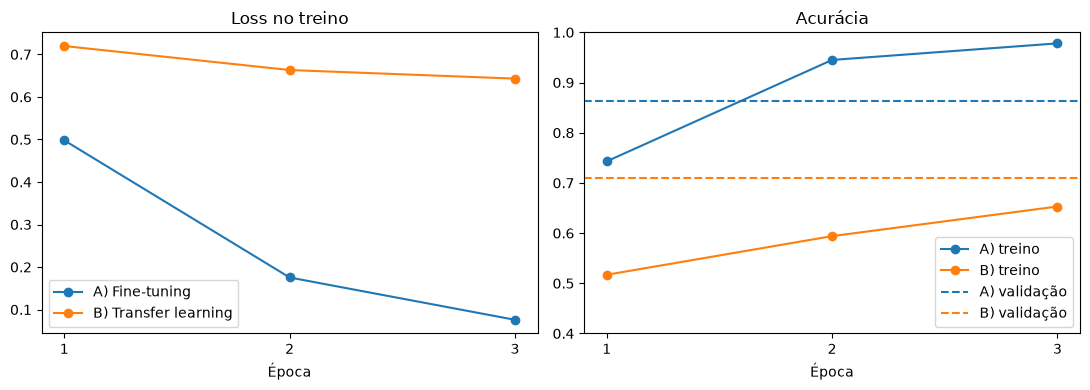

In [17]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
epocas = [h["epoca"] for h in hist_ft]

# Gráfico 1: loss (erro) no treino a cada época. Quanto menor, melhor.
ax1.plot(epocas, [h["loss"] for h in hist_ft], marker="o", label="A) Fine-tuning")
ax1.plot(epocas, [h["loss"] for h in hist_tl], marker="o", label="B) Transfer learning")
ax1.set_title("Loss no treino")
ax1.set_xlabel("Época")
ax1.set_xticks(epocas)
ax1.legend()

# Gráfico 2: acurácia no treino a cada época, com a acurácia final na validação (linhas tracejadas).
ax2.plot(epocas, [h["acuracia"] for h in hist_ft], marker="o", label="A) treino")
ax2.plot(epocas, [h["acuracia"] for h in hist_tl], marker="o", label="B) treino")
ax2.axhline(acc_ft, color="C0", linestyle="--", label="A) validação")
ax2.axhline(acc_tl, color="C1", linestyle="--", label="B) validação")
ax2.set_title("Acurácia")
ax2.set_xlabel("Época")
ax2.set_xticks(epocas)
ax2.set_ylim(0.4, 1.0)
ax2.legend()

plt.tight_layout()
plt.savefig("curvas_treinamento.png", dpi=120)   # salva a figura para usar no README
plt.show()

## 8. Testando frases novas

Frases que o modelo nunca viu, incluindo algumas "pegadinhas": negação (*not bad*),
expectativa frustrada e opinião mista.

In [18]:
def prever(modelo, frases):
    modelo.eval()
    entradas = tokenizer(frases, padding=True, truncation=True,
                         max_length=MAX_LENGTH, return_tensors="pt").to(device)
    with torch.no_grad():
        logits = modelo(**entradas).logits
    probabilidades = torch.softmax(logits, dim=1)       # transforma os 2 logits em probabilidades
    confianca, classe = probabilidades.max(dim=1)       # classe mais provável e sua probabilidade
    return [f"{NOMES[c.item()]} ({p.item():.0%})" for c, p in zip(classe, confianca)]


frases = [
    "This movie was absolutely fantastic.",
    "This movie was terrible.",
    "The story was boring and predictable.",
    "One of the best movies I have ever seen.",
    "This movie was not bad at all.",
    "I expected much more from this director.",
    "The acting was great, but the plot was a mess.",
]

pd.DataFrame({
    "Frase": frases,
    "A) Fine-tuning": prever(modelo_ft, frases),
    "B) Transfer learning": prever(modelo_tl, frases),
    "B) 20 épocas": prever(modelo_tl20, frases),
})

,Frase,A) Fine-tuning,B) Transfer learning,B) 20 épocas
0,This movie was absolutely fantastic.,positivo (100%),positivo (51%),positivo (64%)
1,This movie was terrible.,negativo (99%),negativo (67%),negativo (91%)
2,The story was boring and predictable.,negativo (99%),negativo (62%),negativo (85%)
3,One of the best movies I have ever seen.,positivo (100%),negativo (55%),negativo (55%)
4,This movie was not bad at all.,positivo (100%),negativo (70%),negativo (87%)
5,I expected much more from this director.,positivo (99%),negativo (58%),negativo (64%)
6,"The acting was great, but the plot was a mess.",negativo (99%),negativo (52%),negativo (70%)


## 9. Conclusões

*(Números da execução salva neste notebook, em uma RTX 5080. Em outra GPU ou na CPU os tempos mudam;
as acurácias devem ficar iguais ou muito próximas, graças à semente fixa.)*

| Estratégia | Parâmetros treináveis | Tempo de treino | Acurácia (validação) |
|---|---|---|---|
| Chute (sempre a classe mais comum) | — | — | 50,9% |
| **A) Fine-tuning completo (BERT)** | 109.483.778 (100%) | ~13 s | **86,2%** |
| B) Transfer learning, 3 épocas | 1.538 (0,0014%) | ~2,5 s | 71,0% |
| B) Transfer learning, 20 épocas (bônus) | 1.538 (0,0014%) | ~17 s | 77,3% |
| *Referência: Llama 3.2 1B, fine-tuning (notebook da aula)* | *1.235.818.496* | *minutos* | *80,2%* |

**1. A troca do LM Head funciona com outro backbone.** Com a mesma receita da aula (1000 frases, 3 épocas,
lr 2e-5), o BERT chegou a **86,2%**, mais que os 80,2% do Llama 3.2 1B no notebook da aula, sendo ~11 vezes menor
e treinando em segundos. Cuidado ao generalizar: é uma única execução, e as 1000 frases sorteadas não são as
mesmas da aula. Ainda assim, faz sentido: o BERT é um *encoder* que lê a frase nos dois sentidos e foi criado
para ser ajustado em tarefas de classificação. O Llama é um *decoder*, feito para gerar texto.

**2. Fine-tuning × transfer learning (exercício 1 da aula):**

- *Parâmetros treináveis:* caem de 109 milhões para **1.538**, só os pesos da cabeça nova (768 × 2 + 2).
- *Tempo:* cada época ficou cerca de **5 vezes mais rápida**, porque não é preciso calcular gradientes nem
  atualizar o corpo do modelo.
- *Resultado:* **bem pior**. Com 3 épocas, 71,0%; mesmo com 20 épocas (mais tempo total que o fine-tuning),
  77,3%, ainda 9 pontos abaixo do fine-tuning.

**3. Por que treinar só a cabeça não basta?** O vetor do `[CLS]` que sai do BERT congelado foi aprendido para
outras tarefas do pré-treino (adivinhar palavras escondidas e dizer se uma frase vem depois da outra), não para
separar opiniões boas e ruins. A cabeça nova é só uma camada linear: ela consegue "traçar uma linha" nesse espaço,
mas não consegue reorganizá-lo. No fine-tuning, as 12 camadas Transformer também se ajustam e **reposicionam os
vetores** de forma que frases positivas e negativas fiquem em regiões diferentes (a ideia do slide sobre o
Transformer mapear "manga" para regiões diferentes do espaço). Resposta à pergunta do slide 27: para esta tarefa,
**treinar só a nova camada não é suficiente**.

**4. Sinais de alerta, mesmo no melhor modelo:**

- *Overfitting:* no fine-tuning, a acurácia de treino chegou a 97,8%, mas a de validação ficou em 86,2%
  (e a loss de validação, 0,44, é bem maior que a de treino, 0,08). Com só 1000 exemplos, o modelo começa a
  "decorar" o treino.
- *Excesso de confiança:* nas frases novas, o modelo A acertou a negação (*"not bad at all"* → positivo),
  mas classificou *"I expected much more from this director"* como positivo **com 99% de confiança**.
  Probabilidade alta não é garantia de acerto.
- O transfer learning de 3 épocas classificou *"One of the best movies I have ever seen"* como negativo:
  com essa acurácia, não dá para usar em produção.

**Curiosidade:** no transfer learning a acurácia de treino (65,3%) ficou *abaixo* da de validação (71,0%).
Não é erro: a de treino é a média ao longo da época, enquanto a cabeça ainda está aprendendo, e é medida com o
*dropout* ligado. A de validação é medida no fim, com o dropout desligado.

### Próximos passos possíveis

- **Exercício 3 da aula:** classificar as mesmas 872 frases com um LLM via prompt (LangChain, N8N...) e comparar a acurácia.
- **Meio-termo entre A e B:** congelar só as primeiras camadas do BERT e treinar as últimas junto com a cabeça.
- **Outros backbones:** basta trocar `MODEL_ID` na célula de configuração, por exemplo `distilbert-base-uncased`
  (menor e mais rápido) ou `roberta-base`.
- **Português:** usar o BERTimbau (`neuralmind/bert-base-portuguese-cased`) com um conjunto de avaliações em português.